# 03 · Environmental distributions and principal component analysis

Separate water and soil PCAs describe environmental variation in `PCA.xlsx`.
Sections 2–5 pool the two lakes; section 6 additionally fits each compartment separately within Loktak and Pumlen.
Each sheet has **80 records = 2 lakes × 2 years × 4 seasons × 5 sites**.
All measured columns are included in their respective PCA; identifiers are excluded.
The soil PCA contains SOC concentration as supplied, not calculated soil carbon stock.

Run **Kernel → Restart Kernel and Run All Cells** using **Python (ler)**, with this notebook
in `ipynb_files_1/`, and the three Excel files and `ecological_data.py` in the parent project folder. Each notebook runs independently.
Figures are displayed here and saved as 300-dpi PNGs and vector PDFs under `ipynb_files_1/figures/`.
The source workbooks are read only. Tables are saved under `ipynb_files_1/tables/`.
Plot text uses **Times New Roman**: axis labels, tick labels and legends are all **12 pt**. Each exported figure is **160 mm wide × 106.7 mm high** (height:width = **2:3**). Insert at 160 mm width to preserve these font sizes on A4; check the thesis template’s margins.

Each plot is displayed and saved separately; filenames identify its variable or PCA analysis.
Figures have no titles. Two-lake legends are centred below seasonal and distribution plots; other legends remain at the bottom right; filenames identify variables and PCA analyses. All PCA score plots and biplots combine both years.


## Ecological context and questions

Loktak and Pumlen differ in hydrology, vegetation and human pressures, potentially producing different water and soil physicochemical signatures. These figures describe **seasonal distributions** and the dominant **multivariate environmental gradients**, rather than directly estimating the causal controls on carbon storage.

Each compartment (water, soil) has 80 observations representing two wetlands, two years, four seasons and five sites. In the PCA, environmental variables are standardised because they have different units. A PCA component is an orthogonal linear combination of standardised measurements, not a measured ecological process. PC1/PC2 separation is descriptive and requires independent testing if used to claim statistically distinct groups.

**Design limitation:** The site IDs recur between sampling periods, so visual separation should not be mistaken for independent replication. Environmental variables without verified measurement units are deliberately not assigned invented units.

## Choices

- Each variable gets its own distribution axis. Units absent from the source headers
  are not inferred. Box plots show quartiles and 1.5-IQR whiskers; overlaid dots show
  all observations, pooling the two years (10 records per lake–season, not 10 independent sites).
- Log display is available through `SCALE_OVERRIDES` in the setup cell. The default
  positive-range threshold is 20-fold, excluding pH and temperature. None of the
  current variables needs log scaling after separating the axes.
- PCA uses **untransformed measurements, centred and divided by sample SD**. No
  log transformation, imputation, outlier deletion or variable selection is performed.
- The code labels are cross-checked against the named blocks in `Scatter Plot (1).xlsx`.

In [1]:
FIGURE_GROUP = "03_environment_pca"

from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
import seaborn as sns
from IPython.display import display
from matplotlib_inline.backend_inline import InlineBackend

# Keep inline displays at the same canvas ratio as the saved PNG/PDF files.
InlineBackend.instance().print_figure_kwargs = {"bbox_inches": None}
# Locate the project root when the kernel starts here or in the parent folder.
PROJECT_ROOT = next(
    (folder for folder in (Path.cwd(), *Path.cwd().parents)
     if (folder / "ecological_data.py").is_file()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Run this notebook from the lyn project or ipynb_files_1 folder.")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from ecological_data import (
    ROOT, KEYS, SEASONS, WETLANDS, load_scatter, load_pca,
    decode_pca, load_line_summary, load_heatmaps,
)

NOTEBOOK_DIR = ROOT / "ipynb_files_1"
FIG_DIR = NOTEBOOK_DIR / "figures" / FIGURE_GROUP
FIG_DIR.mkdir(parents=True, exist_ok=True)
TABLE_DIR = NOTEBOOK_DIR / "tables"
TABLE_DIR.mkdir(exist_ok=True)
sns.set_theme(style="ticks", context="paper", palette="colorblind", font="Times New Roman", rc={
    "lines.linewidth": 1, "axes.linewidth": 1, "grid.linewidth": 1, "grid.alpha": 0.4,
    "font.size": 12, "axes.labelsize": 12, "axes.titlesize": 12,
    "xtick.labelsize": 12, "ytick.labelsize": 12,
    "legend.fontsize": 12, "legend.title_fontsize": 12,
    "figure.titlesize": 12, "figure.labelsize": 12,
    "mathtext.fontset": "custom",
    "mathtext.rm": "Times New Roman",
    "mathtext.it": "Times New Roman:italic",
    "mathtext.bf": "Times New Roman:bold",
    "figure.dpi": 110, "savefig.dpi": 300,
    "axes.spines.top": False, "axes.spines.right": False,
    "pdf.fonttype": 42, "savefig.bbox": None,
})
# Fixed exported canvas: 160 mm wide, height:width = 2:3.
FIGSIZE = (160 / 25.4, (160 * 2 / 3) / 25.4)

PALETTE = dict(zip(WETLANDS, sns.color_palette("colorblind", 2)))
MARKERS = dict(zip(SEASONS, ["o", "s", "^", "D"]))
LABELS = {
    "Soil_stock": r"Soil carbon stock (Mg C ha$^{-1}$)",
    "Phyto_carbon": "Phytoplankton carbon\n(unit not supplied)",
    "TBC": r"Total biomass carbon (Mg C ha$^{-1}$)",
    "Soil_Temp": "Soil temperature", "Water_Temp": "Water temperature",
    "Soil_pH": "Soil pH", "Water_pH": "Water pH", "BD": "Bulk density (g cm$^{-3}$)",
    "Moisture": "Soil moisture", "SOC": "Soil organic carbon (SOC)",
    "N": "Available nitrogen", "P": "Available phosphorus", "K": "Available potassium",
    "TDS": "Total dissolved solids (TDS)", "EC": "Electrical conductivity (EC)",
    "CO2": r"Free CO$_2$", "Turbidity": "Turbidity", "DO": "Dissolved oxygen (DO)",
    "BOD": "Biochemical oxygen demand", "COD": "Chemical oxygen demand",
    "Alkalinity": "Alkalinity", "Hardness": "Total hardness",
    "Water_K": "Potassium", "Inorg_P": "Inorg. Phosphorus",
}

def save_show(fig, name):
    """Save both a 300-dpi PNG and a vector PDF; retain the inline notebook plot."""
    for extension in ["png", "pdf"]:
        fig.savefig(FIG_DIR / f"{name}.{extension}", bbox_inches=None, facecolor="white")
    plt.show()
    plt.close(fig)

# Display-only choices: no log transform is applied to correlation or PCA inputs.
# Set an entry to "log" or "linear" to override the default for that variable.
SCALE_OVERRIDES = {}
def axis_scale(values, variable):
    values = np.asarray(values, dtype=float)
    assert np.isfinite(values).all()
    if variable in SCALE_OVERRIDES:
        choice = SCALE_OVERRIDES[variable]
    elif "pH" in variable or "Temp" in variable:
        choice = "linear"
    else:
        choice = "log" if values.min() > 0 and values.max()/values.min() >= 20 else "linear"
    assert choice in {"linear", "log"}
    if choice == "log" and np.any(values <= 0):
        raise ValueError(f"Cannot use log scale for nonpositive {variable} values.")
    return choice

def set_numeric_axis(ax, axis, values, variable):
    scale = axis_scale(values, variable)
    getattr(ax, f"set_{axis}scale")(scale)
    getattr(ax, f"set_{axis}label")(LABELS.get(variable, variable) + (" [log scale]" if scale == "log" else ""))

print(f"Python {sys.version.split()[0]} | pandas {pd.__version__} | seaborn {sns.__version__}")
print(f"Figures: {FIG_DIR}")

Python 3.10.18 | pandas 2.3.0 | seaborn 0.13.2
Figures: /Users/phurailatpamhemantakumar/phd/mypackages/lyn/ipynb_files_1/figures/03_environment_pca


In [2]:
raw = load_pca()
frames = {name:decode_pca(frame) for name,frame in raw.items()}
scatter, _ = load_scatter()
for name, frame in frames.items():
    shared = [c for c in frame if c in scatter and c not in KEYS]
    paired = frame.merge(scatter, on=KEYS, suffixes=("_pca","_named"),validate="one_to_one")
    for variable in shared:
        assert np.allclose(paired[variable+"_pca"],paired[variable+"_named"],rtol=0,atol=1e-10)

variables = {name:[c for c in frame if c not in KEYS] for name,frame in frames.items()}
scale_rows = []
for name,frame in frames.items():
    for variable in variables[name]:
        scale_rows.append({"Compartment":name,"Variable":variable,"Minimum":frame[variable].min(),
                           "Maximum":frame[variable].max(),"Display axis":axis_scale(frame[variable],variable)})
display(pd.DataFrame(scale_rows))
print("Missing values: 0; duplicate sampling keys: 0 in each sheet.")

,Compartment,Variable,Minimum,Maximum,Display axis
0,Water,Water_Temp,16.97,28.53,linear
1,Water,TDS,60.85,107.53,linear
2,Water,EC,104.20,179.33,linear
3,Water,Water_pH,5.85,10.01,linear
4,Water,CO2,5.10,41.86,linear
5,Water,Turbidity,4.55,34.00,linear
6,Water,DO,4.30,9.20,linear
7,Water,BOD,1.17,6.36,linear
8,Water,COD,3.37,15.84,linear
9,Water,Alkalinity,60.00,112.67,linear


Missing values: 0; duplicate sampling keys: 0 in each sheet.


## 1. Distributions by season and wetland

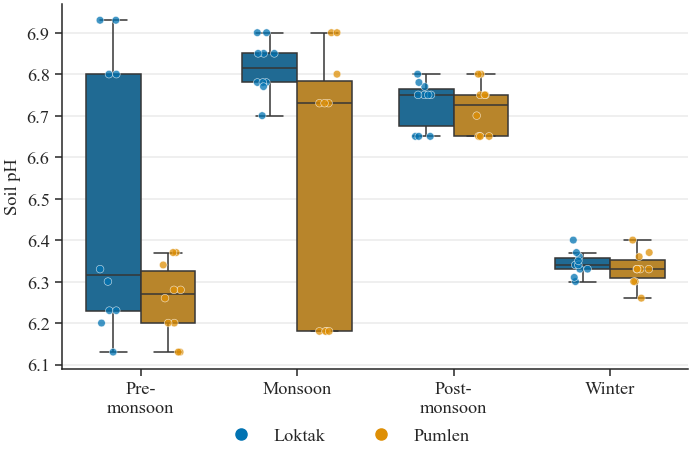

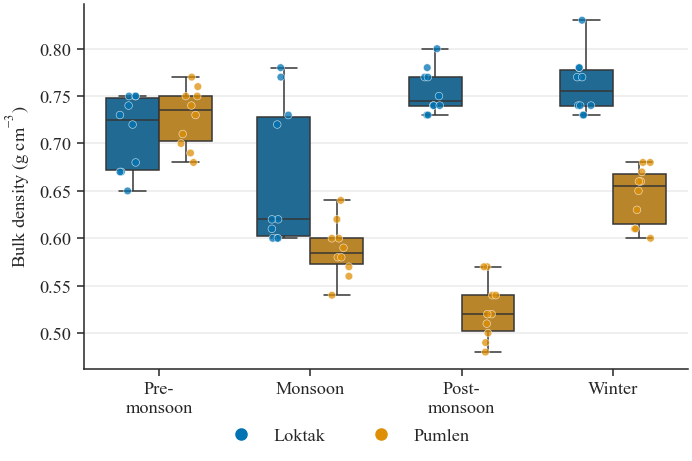

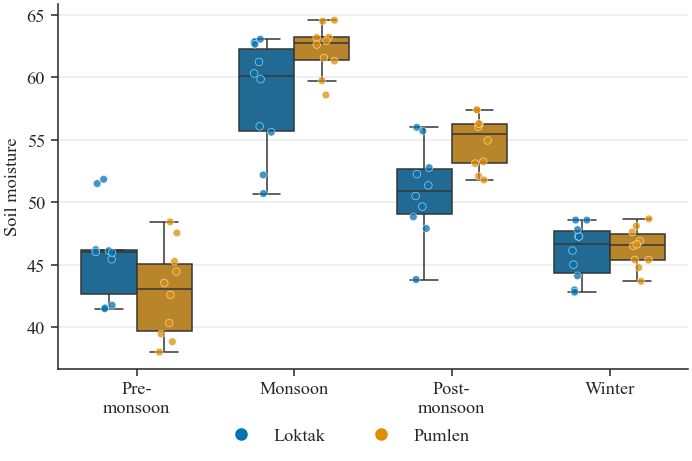

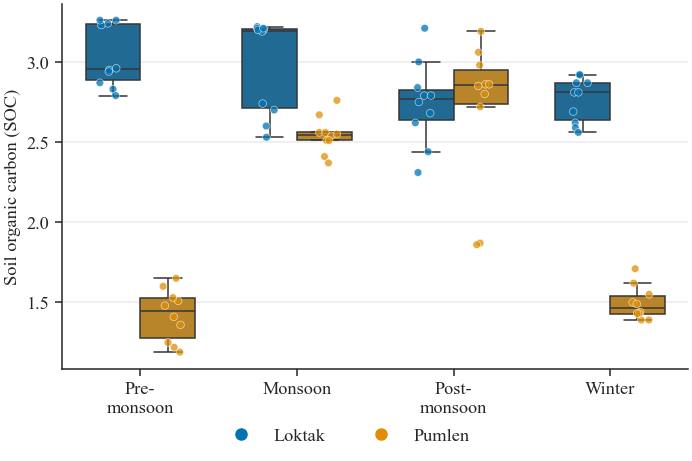

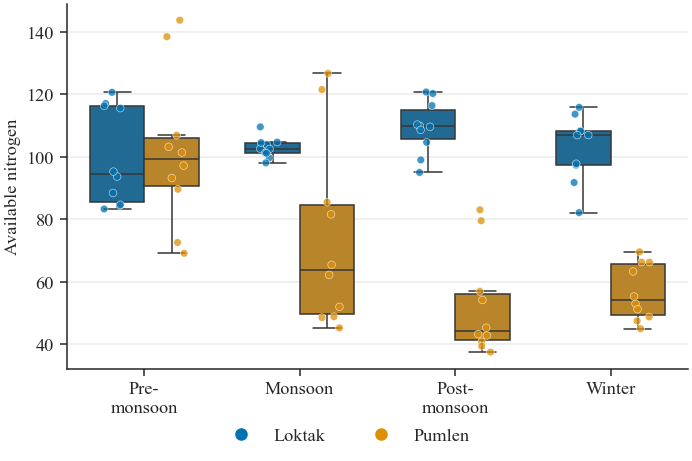

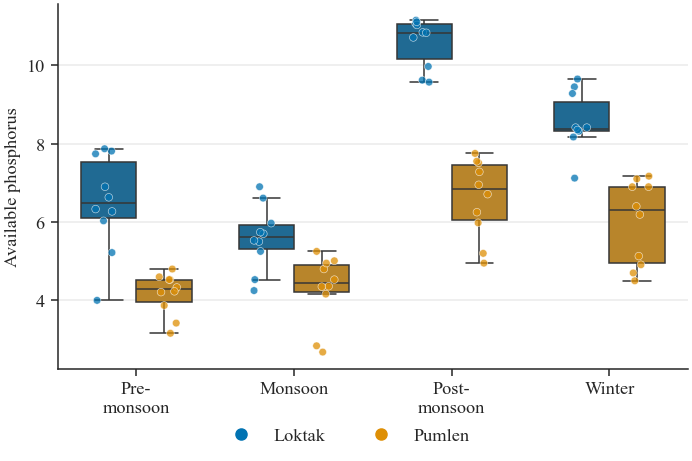

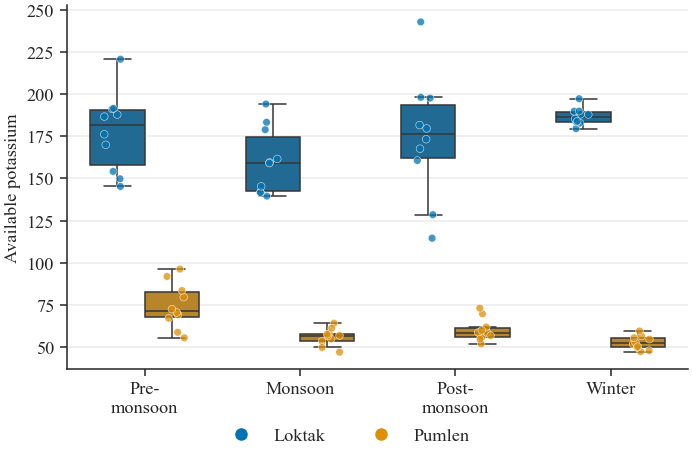

In [3]:
def distribution_figures(compartment):
    frame = frames[compartment]
    for variable in variables[compartment]:
        fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
        sns.boxplot(data=frame, x="Season", y=variable, hue="Wetland", order=SEASONS,
                    hue_order=WETLANDS, palette=PALETTE, showfliers=False, linewidth=1,
                    width=0.7, saturation=0.65, legend=False, ax=ax)
        # Reproducible horizontal jitter; no change to the measured y values.
        np.random.seed(2718)
        sns.stripplot(data=frame, x="Season", y=variable, hue="Wetland", order=SEASONS,
                      hue_order=WETLANDS, palette=PALETTE, dodge=True, jitter=0.12,
                      size=5, alpha=0.75, linewidth=0.4, edgecolor="white", legend=False, ax=ax)
        set_numeric_axis(ax, "y", frame[variable], variable)
        ax.set_xlabel("")
        ax.set_xticks(range(4), ["Pre-\nmonsoon","Monsoon","Post-\nmonsoon","Winter"])
        ax.grid(axis="y", alpha=0.4)
        handles = [Line2D([], [], color=PALETTE[lake], marker="o", linestyle="", label=lake) for lake in WETLANDS]
        fig.legend(handles=handles, loc="outside lower center", ncol=2, frameon=False, markerscale=1.5)

        save_show(fig, f"{compartment.lower()}_distribution_{variable}")

distribution_figures("Soil")

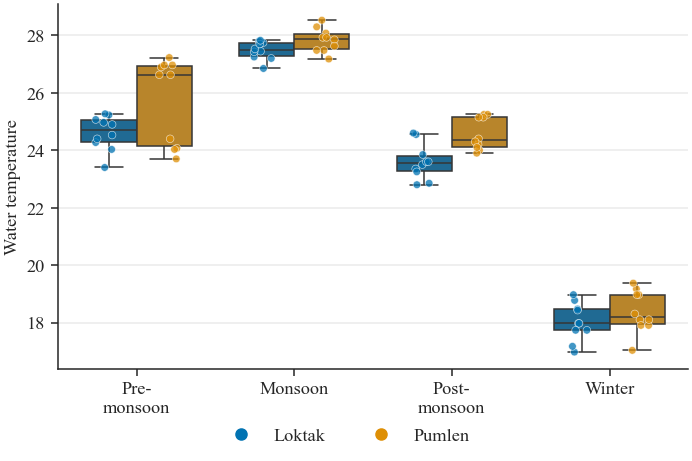

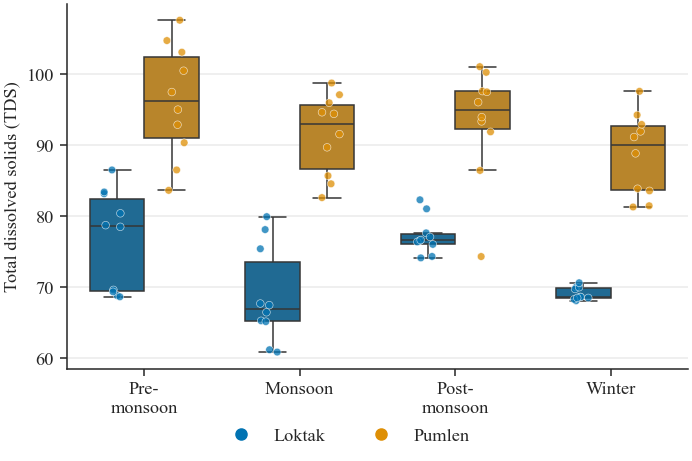

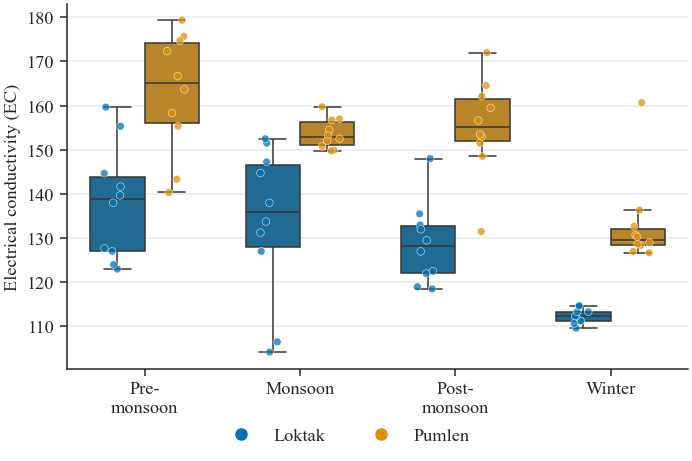

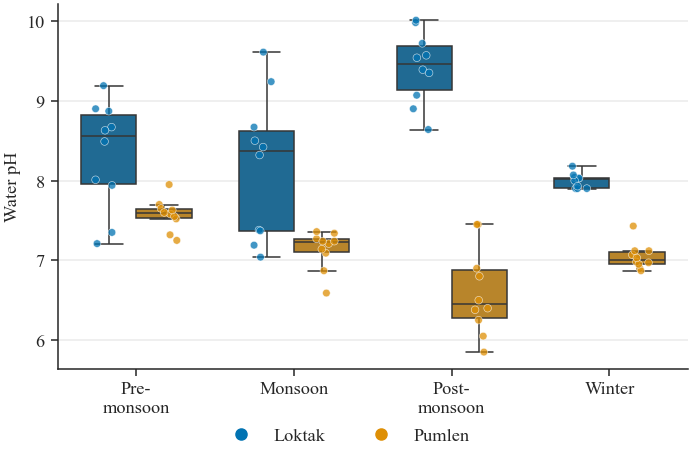

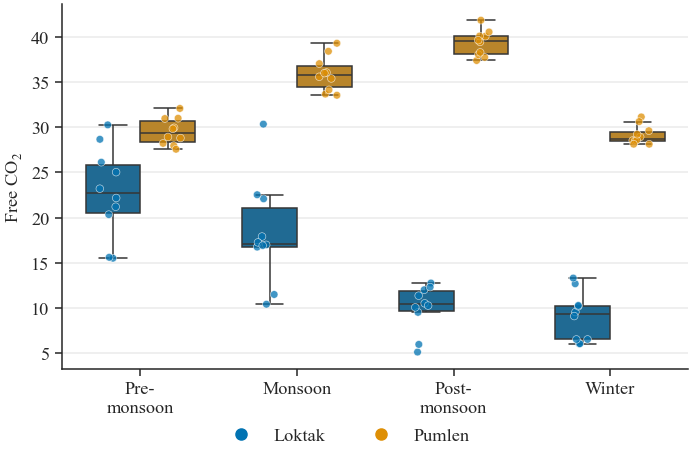

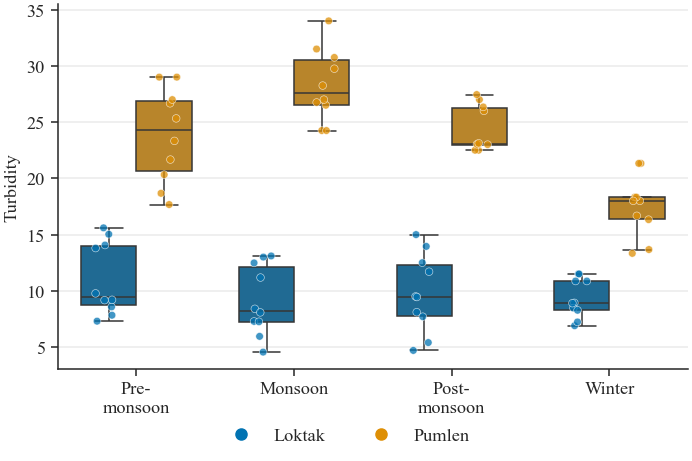

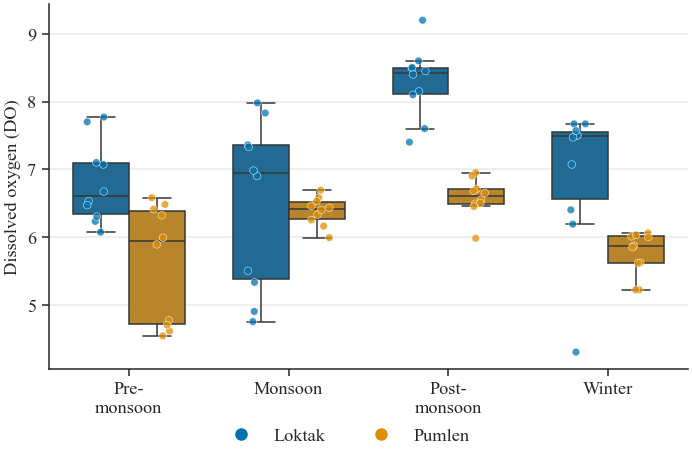

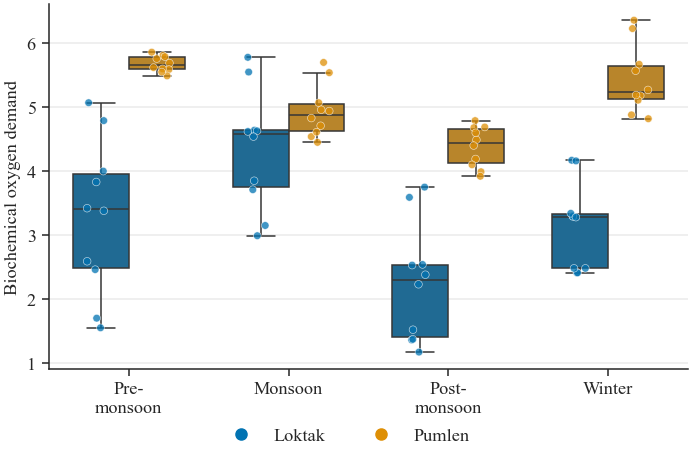

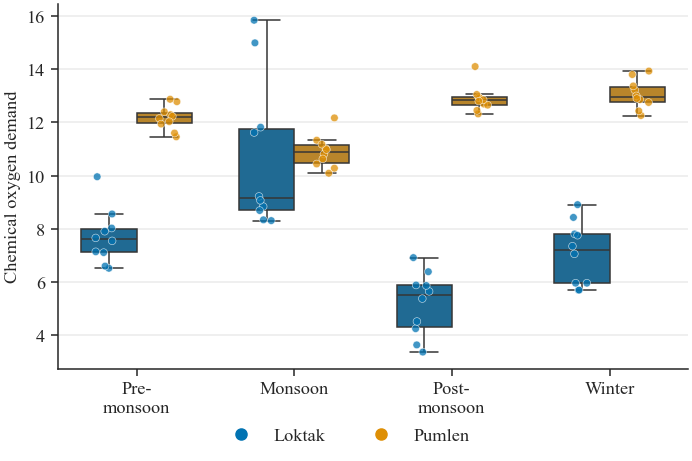

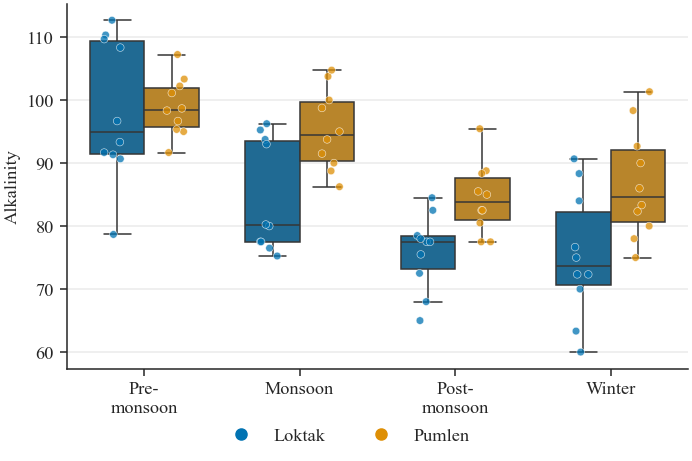

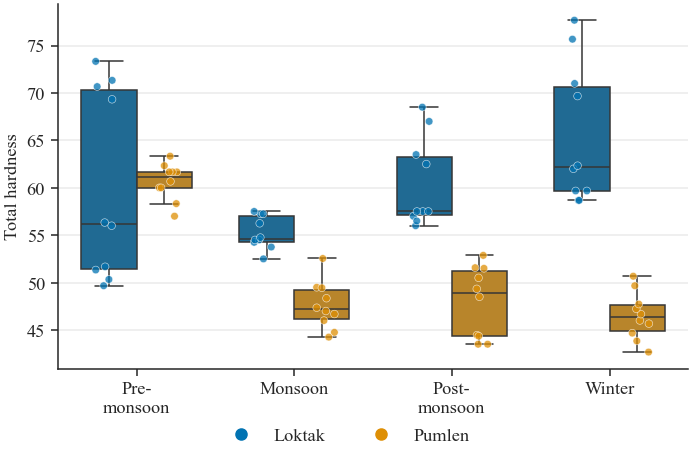

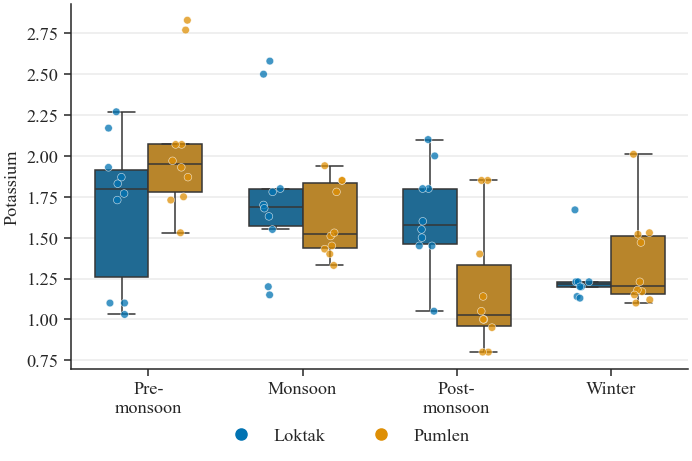

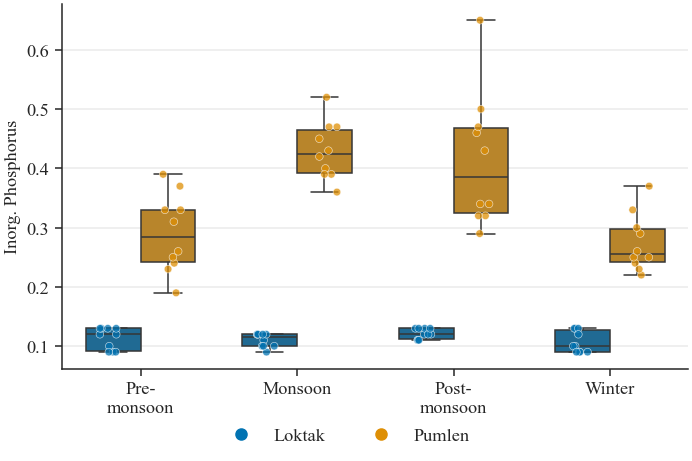

In [4]:
distribution_figures("Water")

## 2. PCA definition and scaling

For each compartment, with $n=80$ and $p$ measured variables,

$$
Z_{ij}=\frac{X_{ij}-\bar X_j}{s_j},\quad
s_j^2=\frac{1}{n-1}\sum_i(X_{ij}-\bar X_j)^2,\quad
Z=UDV^{\mathsf T}.
$$

Scores are $T=ZV=UD$, eigenvalues are $\lambda_k=D_{kk}^2/(n-1)$,
and explained fractions are $\lambda_k/\sum_\ell\lambda_\ell$.
Standardisation gives each variable unit sample variance, so $\sum_k\lambda_k=p$.

Here **weights** mean $V_{jk}$; **correlation loadings** mean
$L_{jk}=\mathrm{corr}(Z_j,T_k)=V_{jk}\sqrt{\lambda_k}$.
These are saved separately to avoid conflating conventions. Signs of an entire PC
can reverse without changing the PCA. Correlated inputs (e.g. EC and TDS) remain
included and can give their shared environmental pattern more representation.

In [5]:
def fit_pca(name, frame, columns):
    """Fit and audit one sample-SD-standardised PCA; export full results."""
    X = frame[columns].astype(float)
    means, scales = X.mean(), X.std(ddof=1)
    assert (scales > 0).all()
    Z = (X-means)/scales
    U, singular_values, Vt = np.linalg.svd(Z.to_numpy(), full_matrices=False)
    scores = U * singular_values
    eigenvalues = singular_values**2 / (len(Z)-1)
    explained_fraction = eigenvalues / eigenvalues.sum()
    pcs = [f"PC{k+1}" for k in range(X.shape[1])]
    weights = pd.DataFrame(Vt.T, index=X.columns, columns=pcs)
    loadings = weights.mul(np.sqrt(eigenvalues), axis="columns")
    score_frame = pd.concat([frame[KEYS].reset_index(drop=True),pd.DataFrame(scores,columns=pcs)],axis=1)
    variance = pd.DataFrame({"PC":pcs, "Eigenvalue":eigenvalues,
                             "Explained (%)":100*explained_fraction,
                             "Cumulative (%)":100*np.cumsum(explained_fraction)})
    # Numerical checks: complete PCA reconstructs Z and the loadings are correlations.
    assert np.allclose(scores @ Vt,Z)
    assert np.isclose(eigenvalues.sum(),X.shape[1])
    direct = np.corrcoef(Z.to_numpy().T,scores.T)[:X.shape[1],X.shape[1]:]
    assert np.allclose(loadings,direct)
    result = dict(scores=score_frame,weights=weights,loadings=loadings,variance=variance)
    for suffix,table in [("scores",score_frame),("weights",weights),("correlation_loadings",loadings),
                          ("variance",variance),("standardisation",pd.DataFrame({"Mean":means,"Sample_SD":scales}))]:
        table.to_csv(TABLE_DIR / f"pca_{name.lower()}_{suffix}.csv",index=suffix not in ["scores","variance"])
    print(f"{name}: PC1+PC2 = {variance['Explained (%)'].iloc[:2].sum():.2f}%")
    display(variance.round(3))
    return result

results = {name: fit_pca(name, frame, variables[name])
           for name, frame in frames.items()}


Water: PC1+PC2 = 65.44%


,PC,Eigenvalue,Explained (%),Cumulative (%)
0,PC1,6.751,51.927,51.927
1,PC2,1.756,13.509,65.436
2,PC3,1.268,9.754,75.190
3,PC4,0.802,6.171,81.361
4,PC5,0.695,5.345,86.706
5,PC6,0.562,4.324,91.030
6,PC7,0.321,2.467,93.498
7,PC8,0.257,1.980,95.477
8,PC9,0.220,1.695,97.172
9,PC10,0.108,0.830,98.002


Soil: PC1+PC2 = 71.77%


,PC,Eigenvalue,Explained (%),Cumulative (%)
0,PC1,2.807,40.106,40.106
1,PC2,2.216,31.662,71.767
2,PC3,0.965,13.783,85.550
3,PC4,0.435,6.218,91.768
4,PC5,0.282,4.027,95.795
5,PC6,0.233,3.322,99.117
6,PC7,0.062,0.883,100.000


## 3. Scores and explained variance

Separate scree plots for all six fitted PCAs are collected in section 8. They show how much variance each component retains. Points in the scores
plot are individual records, coloured by lake and shaped by season. Nearby points
have similar projections onto PC1–PC2; differences in the remaining PCs are not shown.
Both years are combined in every PCA biplot in section 7. Standalone score plots and correlation circles are omitted to avoid duplicate views.

**For the thesis:** retain the scree plot as supporting evidence for the number of components discussed. It can go in an appendix if the main text gives eigenvalues, individual and cumulative explained variance, and explains the component choice. PC1–PC2 is a display choice, not proof that two components adequately represent all variables. The summary tables below show four PCs for consistency with the loading heatmaps, not as an automatic retention rule.

Reference: [Minitab: interpreting PCA statistics and graphs](https://support.minitab.com/en-us/minitab/help-and-how-to/statistical-modeling/multivariate/how-to/principal-components/interpret-the-results/all-statistics-and-graphs/).


## 4. PCA loading directions and complete loading tables

For readability, the combined biplot labels the **five best-represented variables in PC1–PC2**,
ranked by $L_{j1}^2+L_{j2}^2$. This only selects displayed arrows; PCA still includes
every measured variable. Arrows show the correlation loadings on the unit circle. Their lengths are not score units.

All variable–PC correlations are shown by colour in the separate heatmap for the first four
PCs, without numeric cell annotations. Exact values are saved for every PC in the CSV tables. Similar arrow directions indicate similar projections;
interpretation is weaker when much of a variable's variance lies outside PC1–PC2.

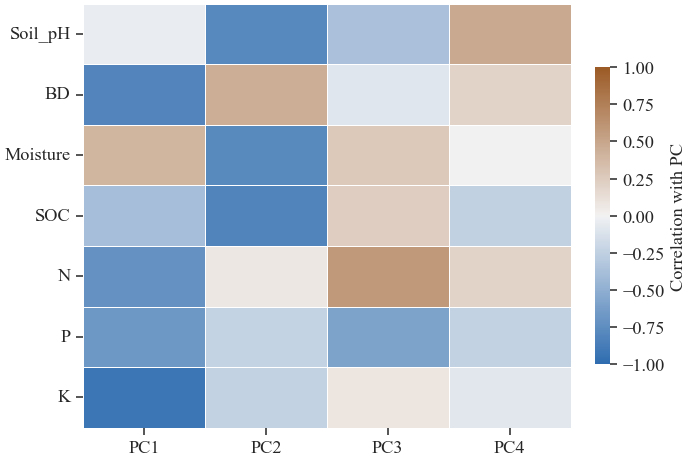

,Variance fraction represented on PC1–PC2
Soil_pH,0.622
BD,0.854
Moisture,0.770
SOC,0.823
N,0.530
P,0.511
K,0.913


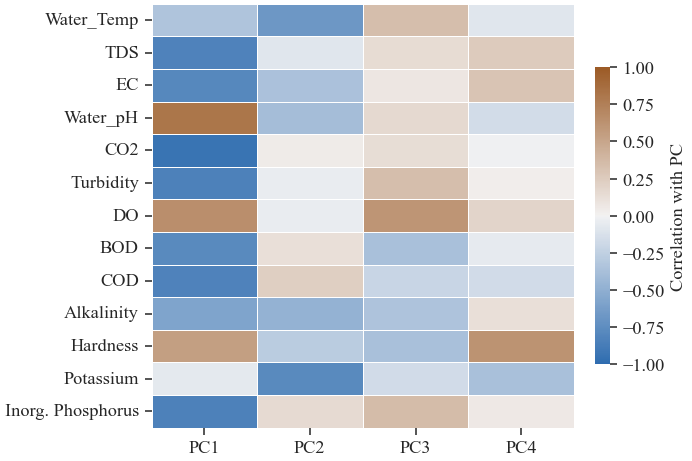

,Variance fraction represented on PC1–PC2
Water_Temp,0.566
TDS,0.706
EC,0.764
Water_pH,0.815
CO2,0.881
Turbidity,0.703
DO,0.425
BOD,0.617
COD,0.749
Alkalinity,0.567


In [6]:
def pca_loading_figures(name):
    """Print-friendly PCA correlation-loading matrix.

    The matrix complements the combined biplots in section 7.
    """
    result = results[name]
    loadings = result["loadings"]
    display_labels = {"Water_K": "Potassium", "Inorg_P": "Inorg. Phosphorus"}
    pc1, pc2 = result["variance"]["Explained (%)"].iloc[:2]
    represented = loadings[["PC1", "PC2"]].pow(2).sum(axis=1)
    selected = represented.nlargest(5).index

    # Comprehensive loadings in a separate figure, not compressed beside scores.
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    sns.heatmap(loadings.iloc[:, :4].rename(index=display_labels),
                cmap=sns.diverging_palette(250, 35, s=85, l=45, as_cmap=True),
                vmin=-1, vmax=1, center=0, annot=False,
                linewidths=0.6,
                cbar_kws={"label":"Correlation with PC", "shrink":0.7}, ax=ax)
    ax.set( xlabel="", ylabel="")
    ax.tick_params(axis="y", rotation=0)
    save_show(fig, f"pca_{name.lower()}_loading_heatmap")
    display(represented.rename("Variance fraction represented on PC1–PC2").to_frame().round(3))

pca_loading_figures("Soil")
pca_loading_figures("Water")

## 5. Thesis-style PCA summary tables

The following tables use the layout of the supplied example: variable–component correlations, followed by eigenvalues, explained variance and cumulative variance. Values come from the **existing pooled PCA for each compartment** (80 records), not from the example image. Soil and water remain separate analyses; neither is labelled “Site-I” or “Site-II”.

Entries for variables are correlation loadings $L_{jk}=V_{jk}\sqrt{\lambda_k}$, not eigenvector weights. They are dimensionless because the PCA uses standardised variables. Tables display PC1–PC4 to three decimal places; the CSV files retain all components at full precision. The four displayed components are not a new selection criterion. A separate cumulative-variance plot accompanies each table. Table figures are taller as needed to keep 12-pt text readable.


,PC1,PC2,PC3,PC4
pH,-0.043,-0.788,-0.364,0.481
Bulk density (BD),-0.806,0.452,-0.087,0.202
Moisture (MC),0.406,-0.778,0.267,0.001
Organic carbon (SOC),-0.389,-0.820,0.240,-0.244
Nitrogen (N),-0.725,0.067,0.585,0.203
Phosphorus (P),-0.676,-0.232,-0.589,-0.237
Potassium (K),-0.926,-0.237,0.082,-0.081
Eigenvalue,2.807,2.216,0.965,0.435
Explained (%),40.106,31.662,13.783,6.218
Cumulative (%),40.106,71.767,85.550,91.768


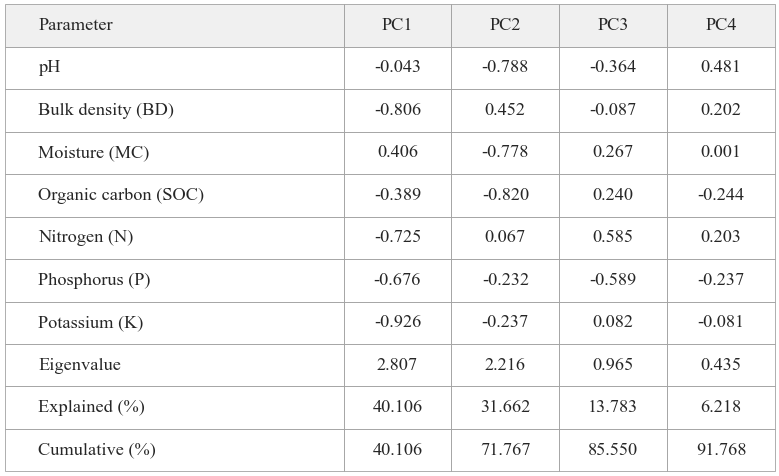

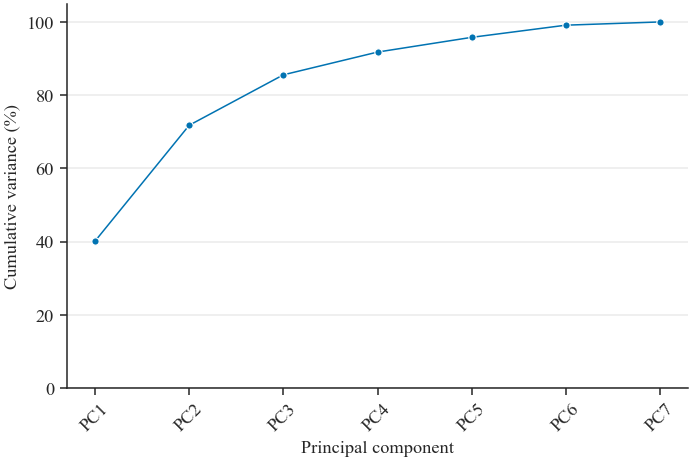

,PC1,PC2,PC3,PC4
Temperature (T),-0.337,-0.673,0.337,-0.091
TDS,-0.836,-0.088,0.146,0.251
EC,-0.795,-0.364,0.077,0.300
pH,0.813,-0.391,0.159,-0.157
Free CO$_2$,-0.938,0.042,0.134,-0.010
Turbidity,-0.838,-0.040,0.341,0.024
DO,0.650,-0.039,0.608,0.192
BOD,-0.776,0.119,-0.375,-0.061
COD,-0.833,0.234,-0.214,-0.170
Alkalinity,-0.581,-0.478,-0.348,0.119


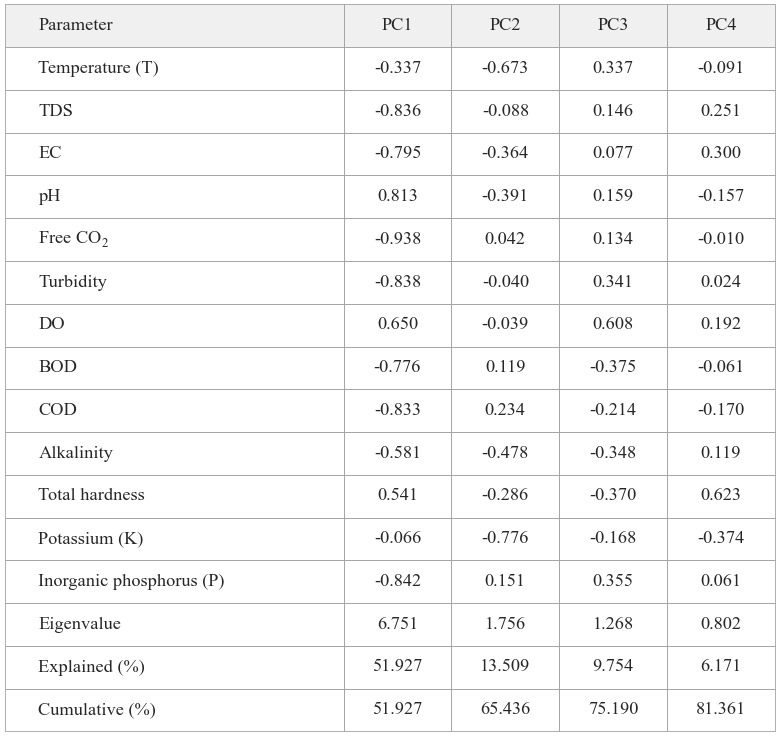

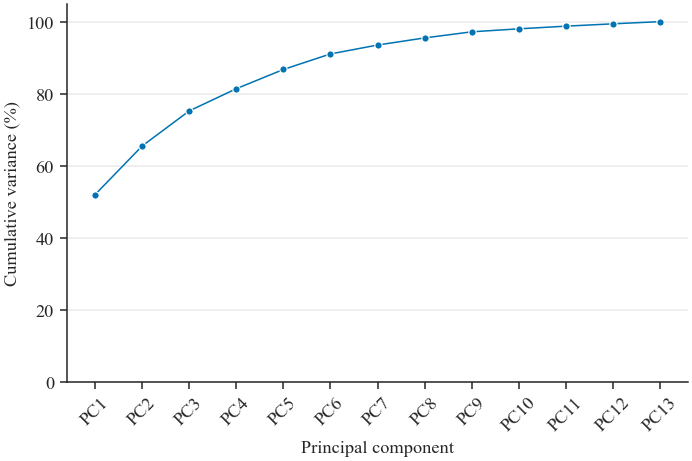

In [7]:
PCA_TABLE_LABELS = {
    "Soil_Temp": "Temperature (T)", "Water_Temp": "Temperature (T)",
    "Soil_pH": "pH", "Water_pH": "pH", "BD": "Bulk density (BD)",
    "Moisture": "Moisture (MC)", "SOC": "Organic carbon (SOC)",
    "N": "Nitrogen (N)", "P": "Phosphorus (P)", "K": "Potassium (K)",
    "TDS": "TDS", "EC": "EC", "CO2": r"Free CO$_2$",
    "Turbidity": "Turbidity", "DO": "DO", "BOD": "BOD", "COD": "COD",
    "Alkalinity": "Alkalinity", "Hardness": "Total hardness",
    "Water_K": "Potassium (K)", "Inorg_P": "Inorganic phosphorus (P)",
}

def pca_summary_figures(name):
    result = results[name]
    variance = result["variance"].set_index("PC")
    summary = pd.concat([
        result["loadings"].rename(index=PCA_TABLE_LABELS),
        variance[["Eigenvalue", "Explained (%)", "Cumulative (%)"]].T,
    ])
    summary.to_csv(TABLE_DIR / f"pca_{name.lower()}_thesis_summary.csv")
    shown = summary.iloc[:, :4]
    display(shown.round(3))

    # A separate table figure: no plot title, 12-pt text, thin rules.
    fig, ax = plt.subplots(figsize=(180 / 25.4, (10 * (len(shown) + 1)) / 25.4),
                           layout="constrained")
    ax.set_axis_off()
    table = ax.table(
        cellText=[[label] + [f"{value:.3f}" for value in row]
                  for label, row in shown.iterrows()],
        colLabels=["Parameter"] + list(shown.columns),
        colWidths=[0.44] + [0.14] * len(shown.columns),
        cellLoc="center", bbox=[0, 0, 1, 1],
    )
    table.auto_set_font_size(False)
    table.set_fontsize(12)
    for (row, col), cell in table.get_celld().items():
        cell.set_edgecolor("0.6")
        cell.set_linewidth(0.5)
        cell.get_text().set_fontfamily("Times New Roman")
        if row == 0:
            cell.set_facecolor("0.94")
        if col == 0:
            cell.get_text().set_ha("left")
    save_show(fig, f"pca_{name.lower()}_thesis_summary")

    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    sns.lineplot(data=result["variance"], x="PC", y="Cumulative (%)",
                 marker="o", color=PALETTE["Loktak"], linewidth=1,
                 errorbar=None, ax=ax)
    ax.set(xlabel="Principal component", ylabel="Cumulative variance (%)", ylim=(0, 105))
    ax.tick_params(axis="x", rotation=45)
    ax.grid(axis="y", alpha=0.4)
    save_show(fig, f"pca_{name.lower()}_cumulative_variance")

pca_summary_figures("Soil")
pca_summary_figures("Water")


## 6. Separate PCAs within each lake and compartment

Four additional analyses are fitted: **Loktak soil, Pumlen soil, Loktak water and Pumlen water**. Here “site” in the example is interpreted as the wetland; the five sampling-site identifiers within each wetland remain observations, not separate PCA groups.

Each fit contains **40 records = 2 years × 4 seasons × 5 sampling sites**. Variables are centred and divided by their **within-lake sample SD**, using exactly the same variables as the corresponding pooled compartment analysis. No variables are dropped or transformed. The numerical reconstruction, eigenvalue-sum and loading-correlation checks are repeated for every fit.

Each analysis has its own scree plot, combined-year biplot, loading heatmap, summary table and cumulative-variance plot. Full results and standardisation parameters are saved to CSV.

**Interpretation:** axes from different fits are different linear combinations; PC1 in Loktak is not the same axis as PC1 in Pumlen. Signs may also reverse. Use the pooled PCA for comparing the two lakes in a common coordinate system. Within-lake PCAs describe variation within each lake; repeated observations do not become independent replicates. The PC1–PC4 summary format is a reporting choice, not a rule for retaining four components.


,Compartment,Wetland,Records
0,Soil,Loktak,40


Soil_Loktak: PC1+PC2 = 64.38%


,PC,Eigenvalue,Explained (%),Cumulative (%)
0,PC1,3.088,44.109,44.109
1,PC2,1.419,20.267,64.376
2,PC3,1.096,15.651,80.027
3,PC4,0.805,11.506,91.533
4,PC5,0.310,4.434,95.967
5,PC6,0.197,2.810,98.777
6,PC7,0.086,1.223,100.000


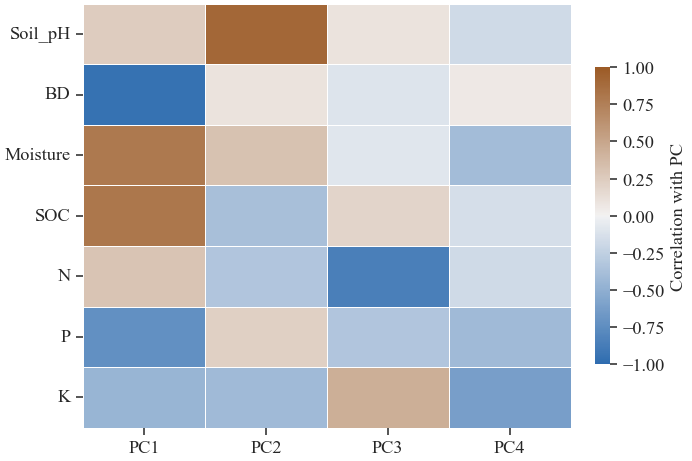

,Variance fraction represented on PC1–PC2
Soil_pH,0.892
BD,0.922
Moisture,0.727
SOC,0.796
N,0.201
P,0.586
K,0.382


,PC1,PC2,PC3,PC4
pH,0.244,0.912,0.094,-0.175
Bulk density (BD),-0.956,0.096,-0.108,0.057
Moisture (MC),0.793,0.313,-0.090,-0.401
Organic carbon (SOC),0.808,-0.378,0.195,-0.147
Nitrogen (N),0.299,-0.334,-0.852,-0.176
Phosphorus (P),-0.732,0.225,-0.331,-0.415
Potassium (K),-0.456,-0.417,0.439,-0.621
Eigenvalue,3.088,1.419,1.096,0.805
Explained (%),44.109,20.267,15.651,11.506
Cumulative (%),44.109,64.376,80.027,91.533


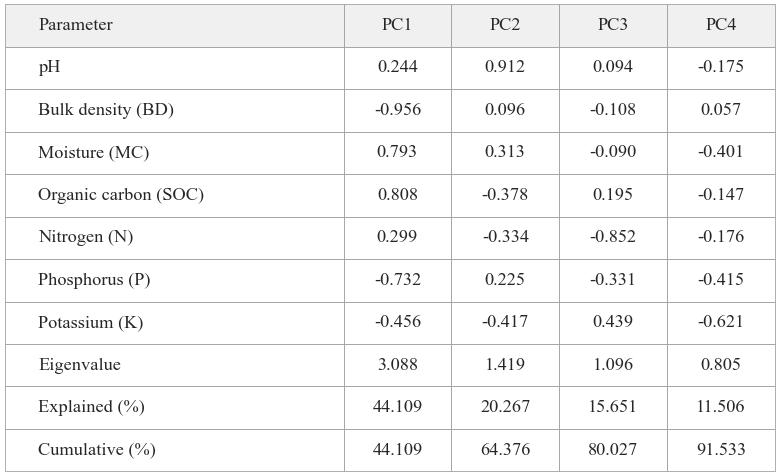

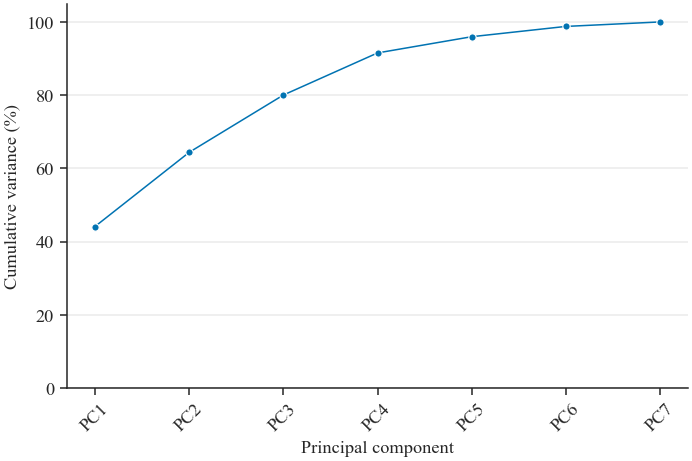

,Compartment,Wetland,Records
0,Soil,Pumlen,40


Soil_Pumlen: PC1+PC2 = 75.41%


,PC,Eigenvalue,Explained (%),Cumulative (%)
0,PC1,3.826,54.655,54.655
1,PC2,1.453,20.756,75.411
2,PC3,0.958,13.691,89.102
3,PC4,0.381,5.442,94.544
4,PC5,0.195,2.787,97.331
5,PC6,0.143,2.037,99.368
6,PC7,0.044,0.632,100.000


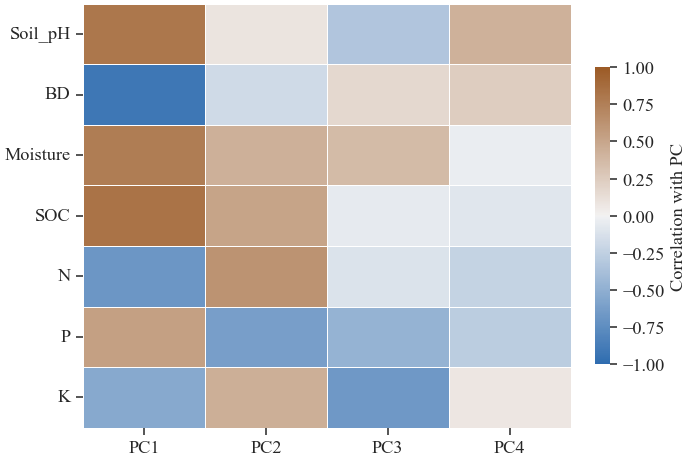

,Variance fraction represented on PC1–PC2
Soil_pH,0.666
BD,0.875
Moisture,0.780
SOC,0.948
N,0.848
P,0.672
K,0.490


,PC1,PC2,PC3,PC4
pH,0.811,0.090,-0.329,0.428
Bulk density (BD),-0.918,-0.179,0.169,0.238
Moisture (MC),0.771,0.431,0.365,-0.034
Organic carbon (SOC),0.829,0.511,-0.057,-0.087
Nitrogen (N),-0.683,0.618,-0.113,-0.228
Phosphorus (P),0.532,-0.624,-0.475,-0.275
Potassium (K),-0.544,0.440,-0.668,0.073
Eigenvalue,3.826,1.453,0.958,0.381
Explained (%),54.655,20.756,13.691,5.442
Cumulative (%),54.655,75.411,89.102,94.544


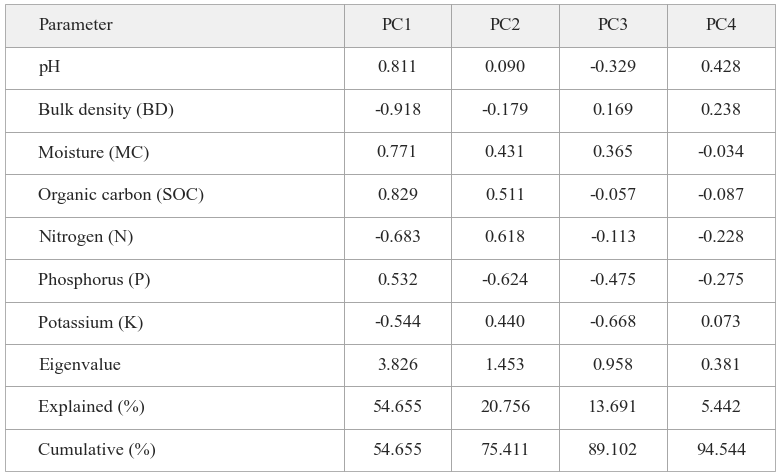

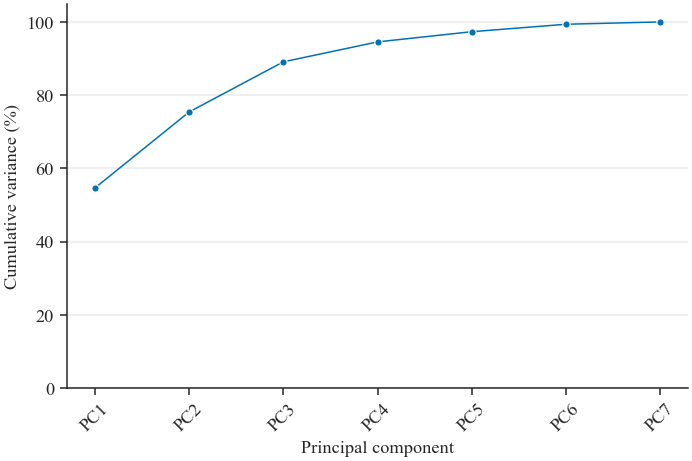

,Compartment,Wetland,Records
0,Water,Loktak,40


Water_Loktak: PC1+PC2 = 53.52%


,PC,Eigenvalue,Explained (%),Cumulative (%)
0,PC1,4.300,33.075,33.075
1,PC2,2.657,20.441,53.516
2,PC3,1.948,14.983,68.499
3,PC4,1.321,10.165,78.663
4,PC5,0.792,6.095,84.758
5,PC6,0.660,5.076,89.834
6,PC7,0.387,2.979,92.813
7,PC8,0.324,2.495,95.309
8,PC9,0.210,1.614,96.923
9,PC10,0.155,1.194,98.117


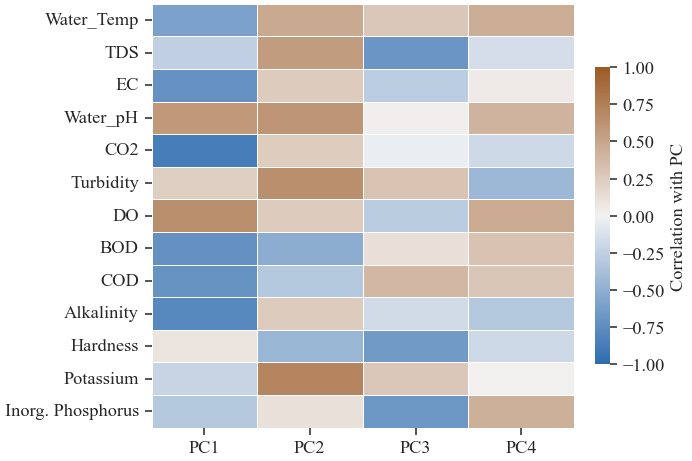

,Variance fraction represented on PC1–PC2
Water_Temp,0.590
TDS,0.375
EC,0.573
Water_pH,0.706
CO2,0.824
Turbidity,0.465
DO,0.478
BOD,0.786
COD,0.600
Alkalinity,0.681


,PC1,PC2,PC3,PC4
Temperature (T),-0.602,0.478,0.280,0.449
TDS,-0.251,0.559,-0.692,-0.154
EC,-0.714,0.251,-0.275,0.052
pH,0.580,0.608,0.019,0.408
Free CO$_2$,-0.874,0.246,-0.037,-0.185
Turbidity,0.227,0.643,0.297,-0.430
DO,0.645,0.250,-0.283,0.471
BOD,-0.725,-0.511,0.119,0.306
COD,-0.707,-0.315,0.376,0.285
Alkalinity,-0.786,0.252,-0.168,-0.307


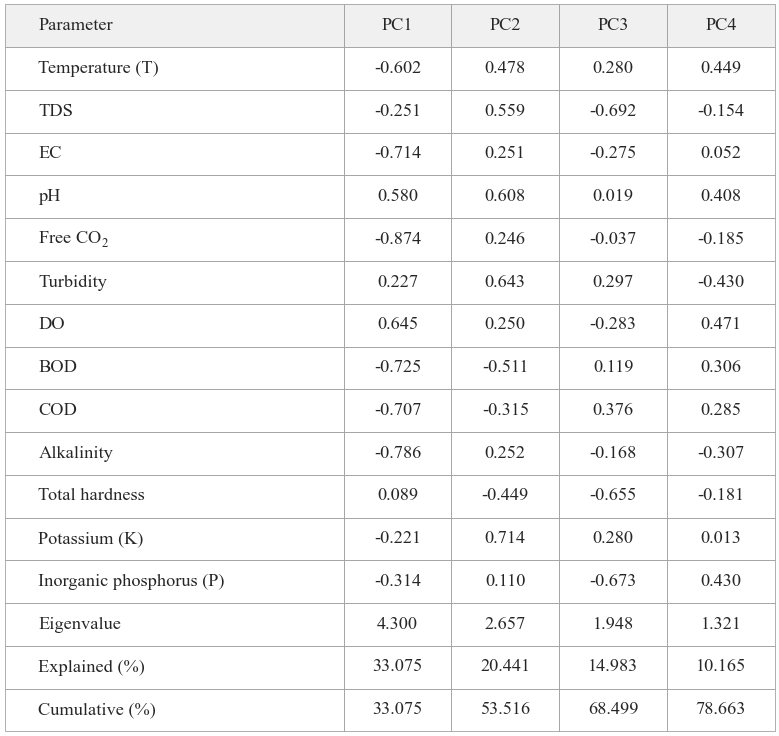

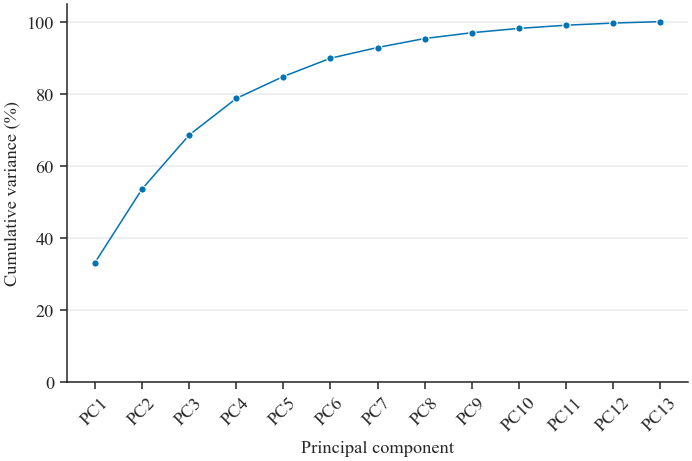

,Compartment,Wetland,Records
0,Water,Pumlen,40


Water_Pumlen: PC1+PC2 = 61.54%


,PC,Eigenvalue,Explained (%),Cumulative (%)
0,PC1,4.116,31.663,31.663
1,PC2,3.884,29.880,61.543
2,PC3,1.455,11.191,72.734
3,PC4,0.846,6.507,79.241
4,PC5,0.777,5.974,85.215
5,PC6,0.553,4.254,89.469
6,PC7,0.451,3.466,92.935
7,PC8,0.356,2.737,95.672
8,PC9,0.211,1.626,97.298
9,PC10,0.136,1.043,98.340


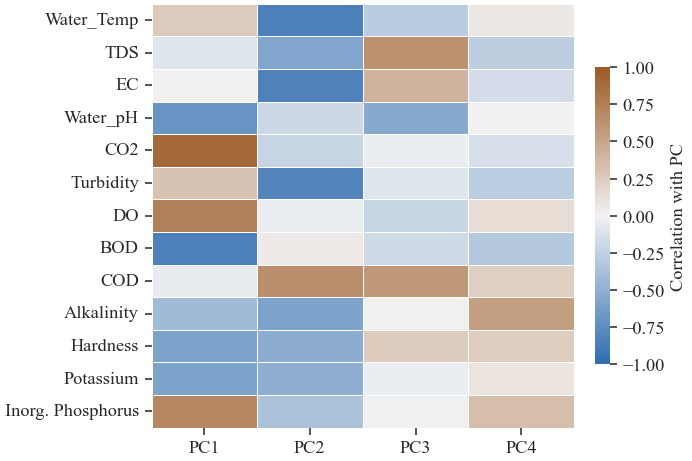

,Variance fraction represented on PC1–PC2
Water_Temp,0.786
TDS,0.334
EC,0.694
Water_pH,0.529
CO2,0.869
Turbidity,0.746
DO,0.556
BOD,0.717
COD,0.424
Alkalinity,0.520


,PC1,PC2,PC3,PC4
Temperature (T),0.259,-0.848,-0.288,0.061
TDS,-0.095,-0.570,0.640,-0.271
EC,0.014,-0.833,0.409,-0.152
pH,-0.701,-0.194,-0.540,-0.000
Free CO$_2$,0.905,-0.223,-0.032,-0.135
Turbidity,0.308,-0.807,-0.099,-0.276
DO,0.744,-0.039,-0.217,0.136
BOD,-0.845,0.050,-0.172,-0.311
COD,-0.051,0.649,0.592,0.229
Alkalinity,-0.418,-0.588,0.011,0.547


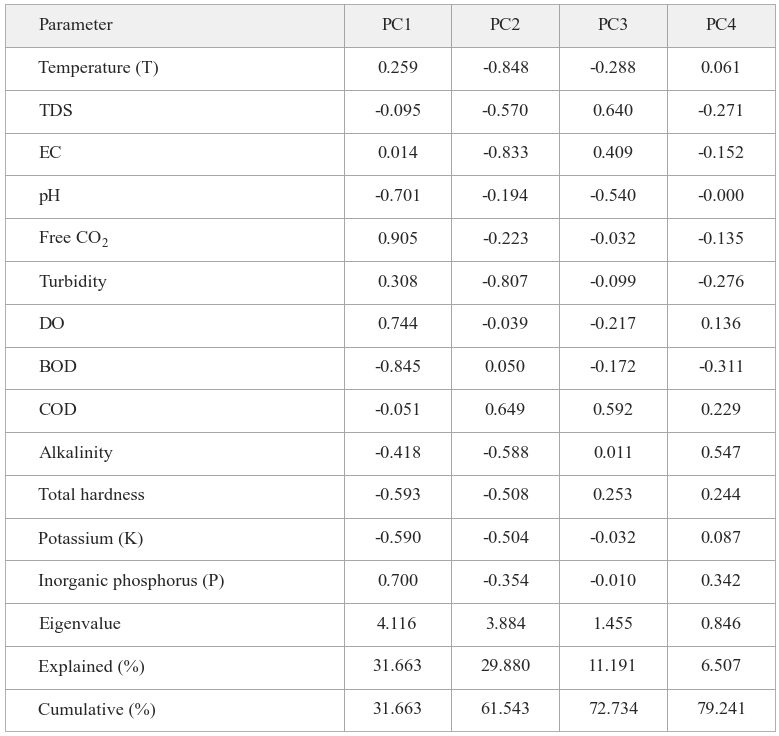

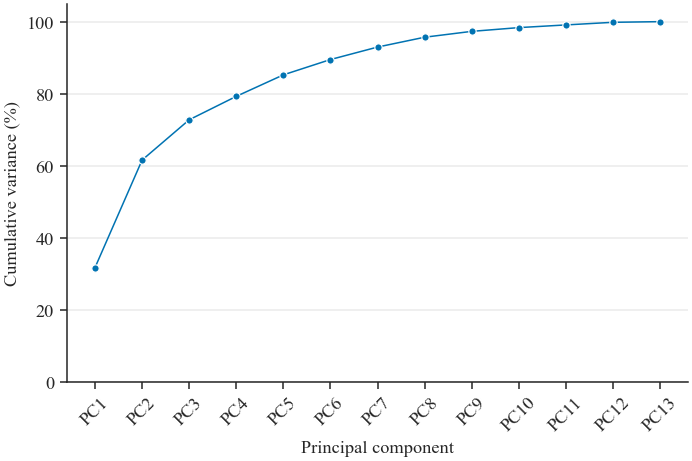

,Compartment,Wetland,Records,PC1 (%),PC2 (%),PC1 + PC2 (%)
0,Soil,Loktak,40,44.109,20.267,64.376
1,Soil,Pumlen,40,54.655,20.756,75.411
2,Water,Loktak,40,33.075,20.441,53.516
3,Water,Pumlen,40,31.663,29.880,61.543


In [8]:
lake_pca_rows = []
for compartment in ["Soil", "Water"]:
    for lake in WETLANDS:
        name = f"{compartment}_{lake}"
        subset = frames[compartment].loc[frames[compartment].Wetland == lake].copy()
        assert len(subset) == 40 and not subset.duplicated(KEYS).any()
        display(pd.DataFrame({"Compartment": [compartment], "Wetland": [lake],
                              "Records": [len(subset)]}))
        results[name] = fit_pca(name, subset, variables[compartment])
        pca_loading_figures(name)
        pca_summary_figures(name)
        variance = results[name]["variance"]
        lake_pca_rows.append({
            "Compartment": compartment, "Wetland": lake, "Records": len(subset),
            "PC1 (%)": variance["Explained (%)"].iloc[0],
            "PC2 (%)": variance["Explained (%)"].iloc[1],
            "PC1 + PC2 (%)": variance["Cumulative (%)"].iloc[1],
        })
lake_pca_summary = pd.DataFrame(lake_pca_rows)
lake_pca_summary.to_csv(TABLE_DIR / "pca_within_lake_variance_summary.csv", index=False)
display(lake_pca_summary.round(3))


## 7. Combined scores and correlation-loading biplots

These combine sample points with the five best-represented variable arrows, ranked by their summed squared PC1–PC2 correlation loadings. All variables still enter the PCA. Colours indicate wetlands and marker shapes indicate seasons. Each biplot shows both years combined, using all records in its fitted PCA.

**Scaling matters.** With scores $T$, eigenvalues $\lambda_k$ and correlation loadings $L$, define $F_{ik}=T_{ik}/\sqrt{\lambda_k}$. Each column of $F$ has unit sample variance. We plot points at $F/c$ and arrows at $cL$, with the **same fixed $c=1.5$ in every figure**. Reciprocal scaling preserves the rank-two reconstruction:

$$
Z_{(2)}=F_{[:,1:2]}L_{[:,1:2]}^{\mathsf T}
       =(F_{[:,1:2]}/c)(cL_{[:,1:2]})^{\mathsf T}.
$$

Read sample coordinates on the bottom/left axes and correlations on the top/right axes. The grey circle represents correlation radius 1 (display radius $c$), **not a confidence ellipse or a boundary for observations**. Numbered arrow labels refer to the key below; short grey leaders move labels away from overlapping arrow tips without changing the arrows.

This view helps relate sample patterns to variable directions, but can be more crowded. Sample distances use standardised PC scores and therefore differ from the raw PCA score coordinates. A point close to an arrow tip is not itself a correlation. Interpret arrow angles cautiously when variables have low representation in PC1–PC2, and do not compare axes from separately fitted lake PCAs as if they were identical.

See [R's PCA biplot scaling documentation](https://www.stat.ethz.ch/R-manual/R-devel/library/stats/html/biplot.princomp.html) for the distinction between score and variable scaling.


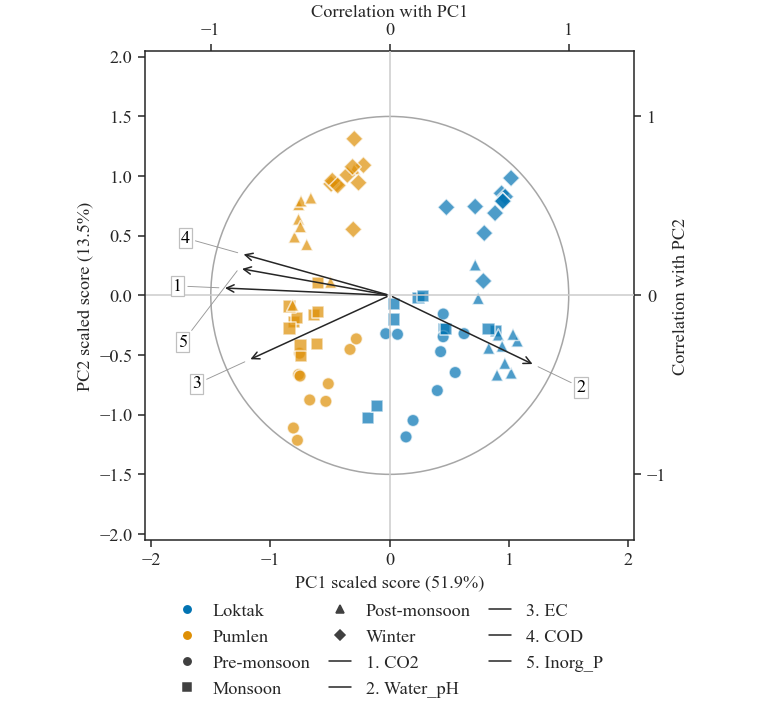

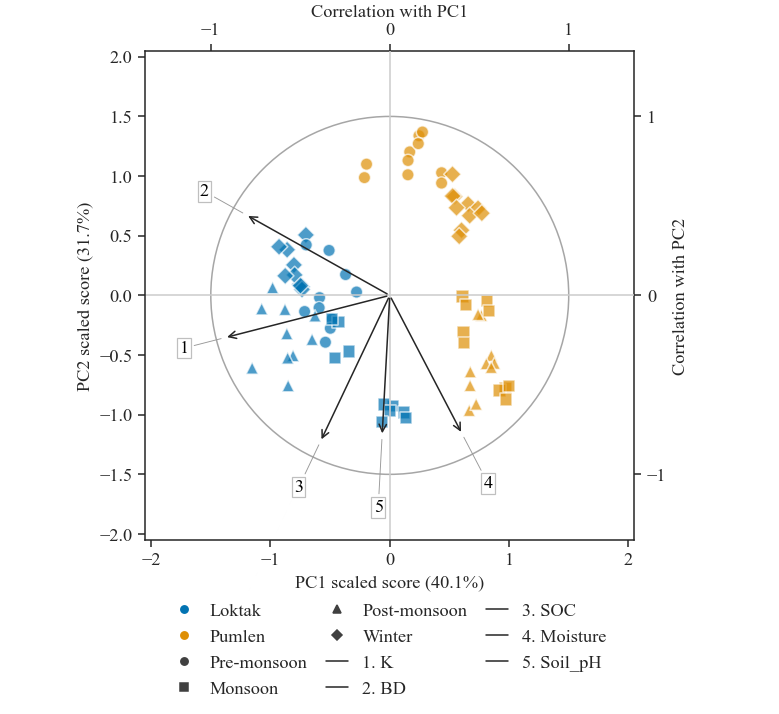

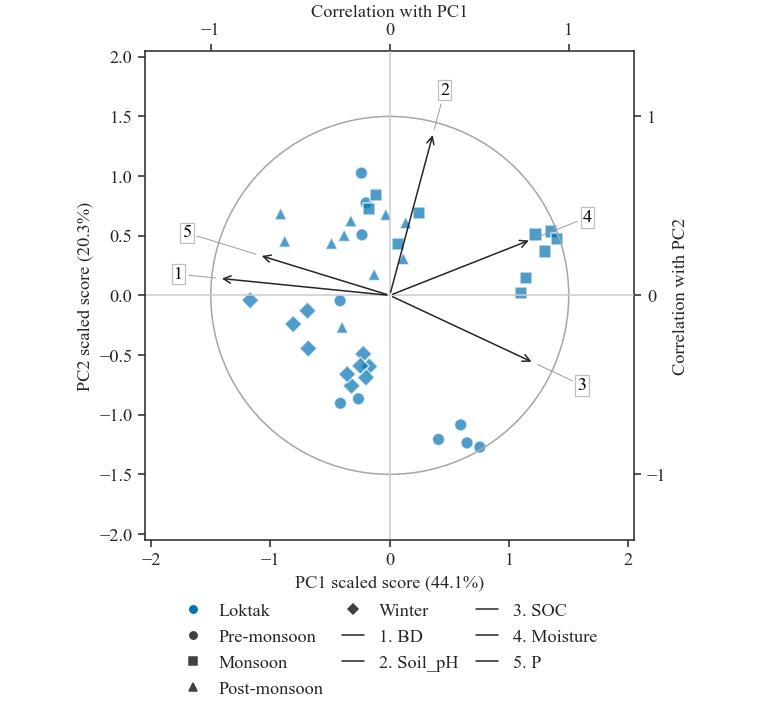

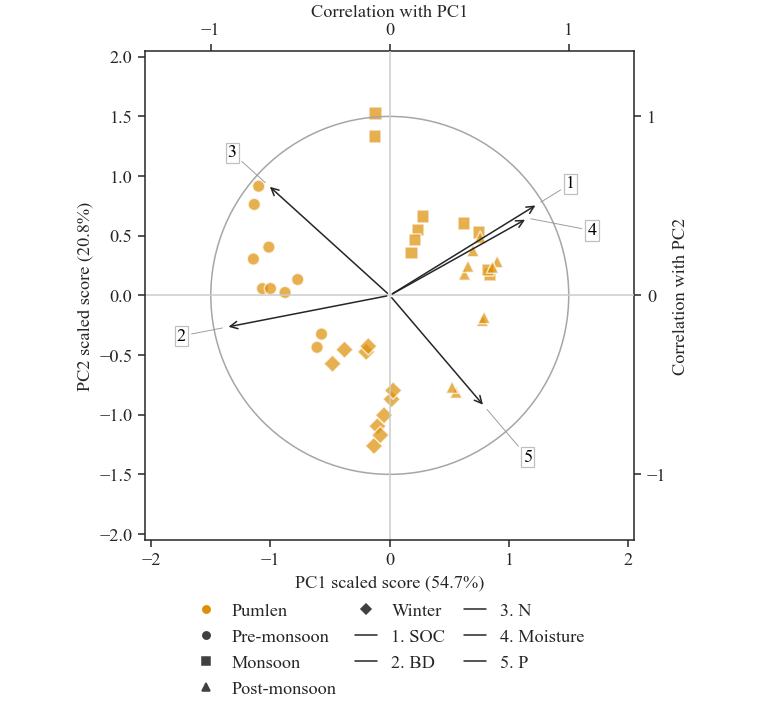

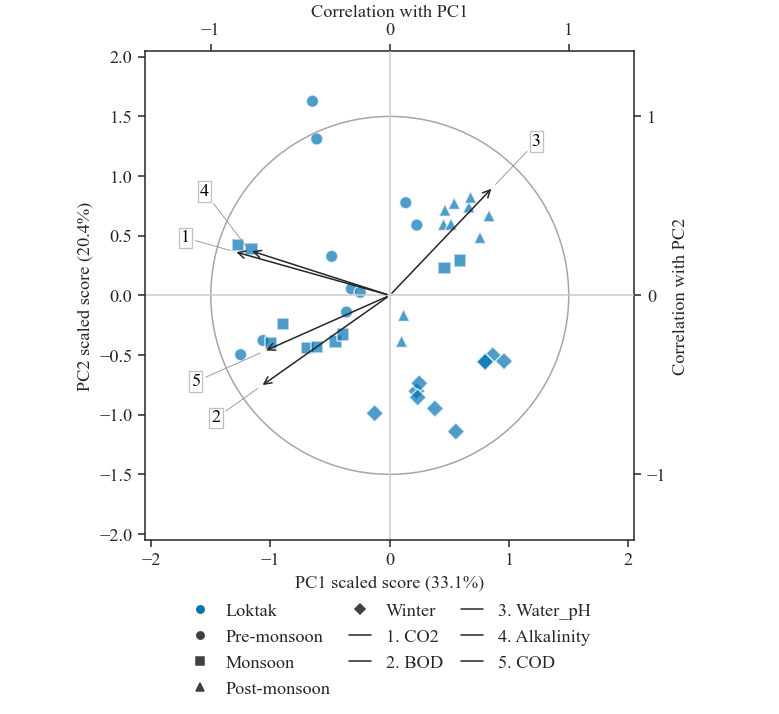

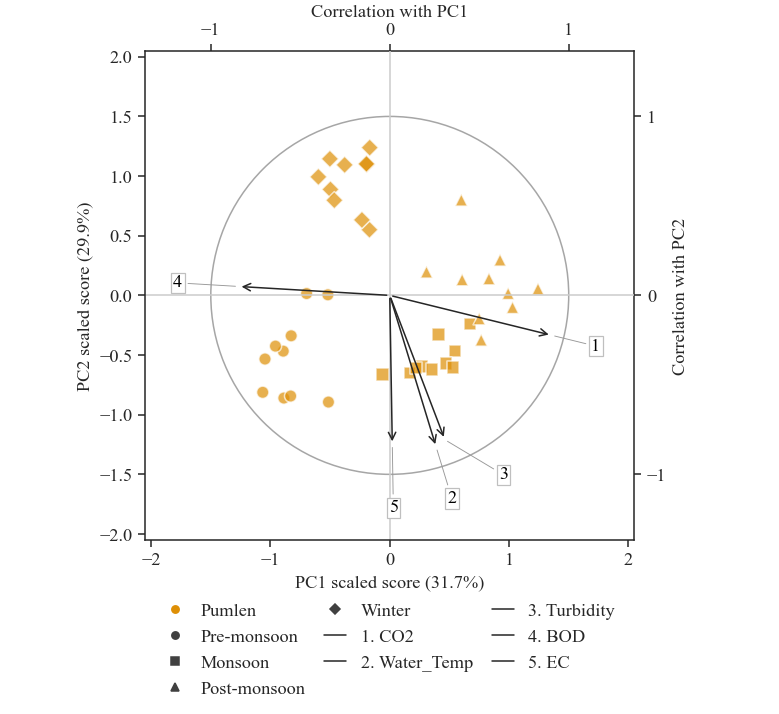

In [9]:
BIPLOT_SCALE = 1.5

def combined_biplots(name):
    result = results[name]
    eigenvalues = result["variance"]["Eigenvalue"].to_numpy()[:2]
    loadings = result["loadings"][["PC1", "PC2"]]
    scaled = result["scores"].copy()
    F = scaled[["PC1", "PC2"]].to_numpy() / np.sqrt(eigenvalues)
    assert np.allclose(F.std(axis=0, ddof=1), 1)
    assert np.allclose((F / BIPLOT_SCALE) @ (BIPLOT_SCALE * loadings.to_numpy()).T,
                       result["scores"][["PC1", "PC2"]].to_numpy()
                       @ result["weights"][["PC1", "PC2"]].to_numpy().T)
    scaled[["PC1", "PC2"]] = F / BIPLOT_SCALE
    selected = loadings.pow(2).sum(axis=1).nlargest(5).index
    limit = max(2.05, np.abs(F / BIPLOT_SCALE).max() * 1.1)
    pc1, pc2 = result["variance"]["Explained (%)"].iloc[:2]
    present = [lake for lake in WETLANDS if lake in set(scaled.Wetland)]
    key = pd.DataFrame({"Number": range(1, 6), "Variable": selected})
    key.to_csv(TABLE_DIR / f"pca_{name.lower()}_biplot_arrow_key.csv", index=False)
    shown = scaled
    fig, ax = plt.subplots(figsize=(180 / 25.4, 165 / 25.4), layout="constrained")
    sns.scatterplot(data=shown, x="PC1", y="PC2", hue="Wetland", style="Season",
                    hue_order=present, style_order=SEASONS, palette=PALETTE,
                    markers=MARKERS, s=65, alpha=0.7, edgecolor="white",
                    linewidth=1, legend=False, ax=ax)
    ax.add_patch(plt.Circle((0, 0), BIPLOT_SCALE, fill=False, color="0.65", lw=1))
    ax.axhline(0, color="0.8", lw=1)
    ax.axvline(0, color="0.8", lw=1)
    used_positions = []
    for number, variable in enumerate(selected, 1):
        tip = BIPLOT_SCALE * loadings.loc[variable].to_numpy()
        ax.annotate("", xy=tip, xytext=(0, 0),
                    arrowprops=dict(arrowstyle="->", color="0.15", lw=1))
        angle = np.arctan2(tip[1], tip[0])
        # Spread only text positions; loading vectors stay exactly unchanged.
        for offset in [0, .2, -.2, .4, -.4, .6, -.6]:
            pos = 1.78 * np.array([np.cos(angle + offset), np.sin(angle + offset)])
            if all(np.linalg.norm(pos - old) > .32 for old in used_positions):
                break
        used_positions.append(pos)
        ax.annotate(str(number), xy=tip, xytext=pos, ha="center", va="center",
                    fontsize=12, color="black",
                    bbox=dict(facecolor="white", edgecolor="0.75", pad=1.5),
                    arrowprops=dict(arrowstyle="-", color="0.6", lw=.6))
    ax.set(xlim=(-limit, limit), ylim=(-limit, limit),
           xlabel=f"PC1 scaled score ({pc1:.1f}%)",
           ylabel=f"PC2 scaled score ({pc2:.1f}%)")
    ax.set_aspect("equal", adjustable="box")
    for position, label in [("top", "Correlation with PC1"), ("right", "Correlation with PC2")]:
        secondary = (ax.secondary_xaxis if position == "top" else ax.secondary_yaxis)(
            position, functions=(lambda x: x / BIPLOT_SCALE, lambda x: x * BIPLOT_SCALE))
        secondary.set_ticks([-1, 0, 1])
        (secondary.set_xlabel if position == "top" else secondary.set_ylabel)(label)
    handles = [Line2D([], [], color=PALETTE[lake], marker="o", linestyle="", label=lake)
               for lake in present]
    handles += [Line2D([], [], color="0.25", marker=MARKERS[s], linestyle="", label=s)
                for s in SEASONS]
    # One combined key, with compact variable names to retain 12-pt text.
    handles += [Line2D([], [], color="0.15", lw=1, label=f"{i}. {v}")
                for i, v in enumerate(selected, 1)]
    fig.legend(handles=handles, loc="outside lower center", ncol=3,
               frameon=False, handlelength=1.2, columnspacing=1)
    save_show(fig, f"pca_{name.lower()}_biplot")

for analysis_name in results:
    combined_biplots(analysis_name)


## 8. Separate scree plots for every fitted PCA

Each figure below corresponds to one fitted PCA: two pooled compartment analyses and four within-lake analyses. Bars show the percentage of total standardised variance explained by each component. These are separate figures, with the same font, dimensions and vertical scale.

Each combined-year biplot corresponds to the scree plot for that fitted PCA. Cumulative variance remains available in the separate cumulative-variance plots and summary tables above.


In [10]:
def pca_scree(name):
    variance = results[name]["variance"]
    fig, ax = plt.subplots(figsize=FIGSIZE, layout="constrained")
    sns.barplot(data=variance,x="PC",y="Explained (%)",color=PALETTE["Loktak"],ax=ax)
    
    ax.set(xlabel="Principal component",ylabel="Variance (%)",ylim=(0,105))
    ax.tick_params(axis="x",rotation=45)
    
    save_show(fig, f"pca_{name.lower()}_scree")



### Soil — both lakes pooled

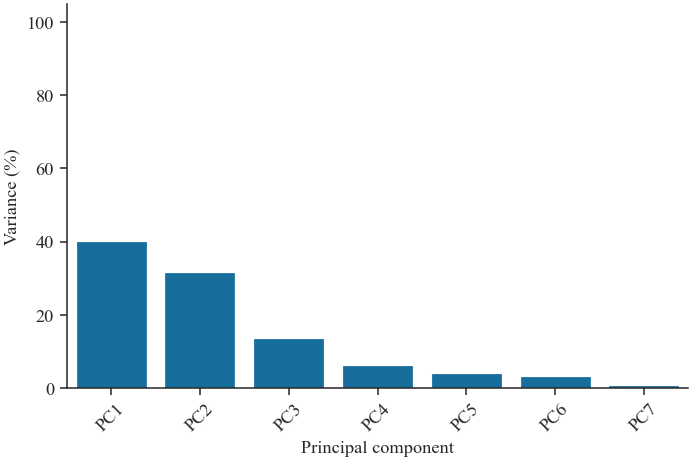

In [11]:
pca_scree("Soil")

### Water — both lakes pooled

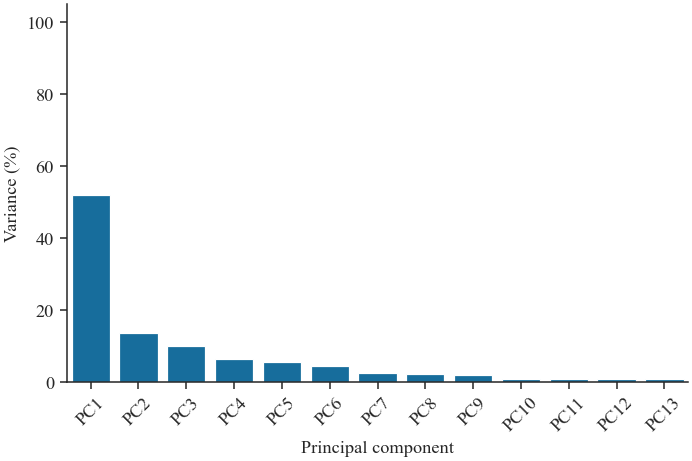

In [12]:
pca_scree("Water")

### Soil — Loktak

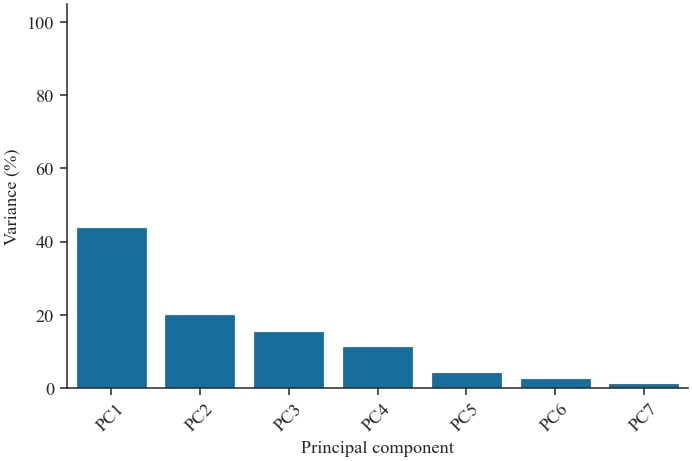

In [13]:
pca_scree("Soil_Loktak")

### Soil — Pumlen

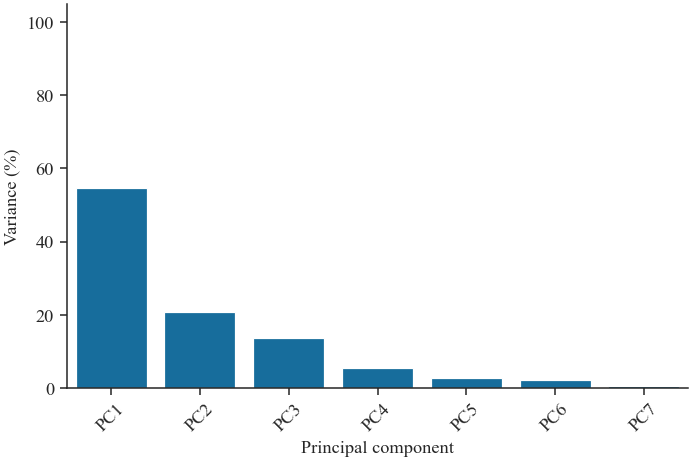

In [14]:
pca_scree("Soil_Pumlen")

### Water — Loktak

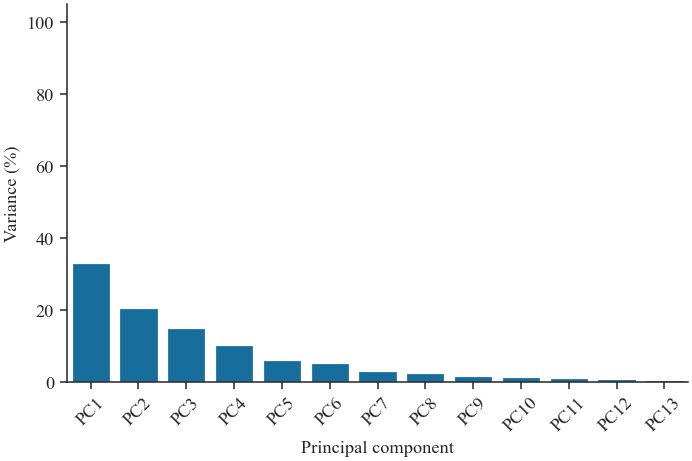

In [15]:
pca_scree("Water_Loktak")

### Water — Pumlen

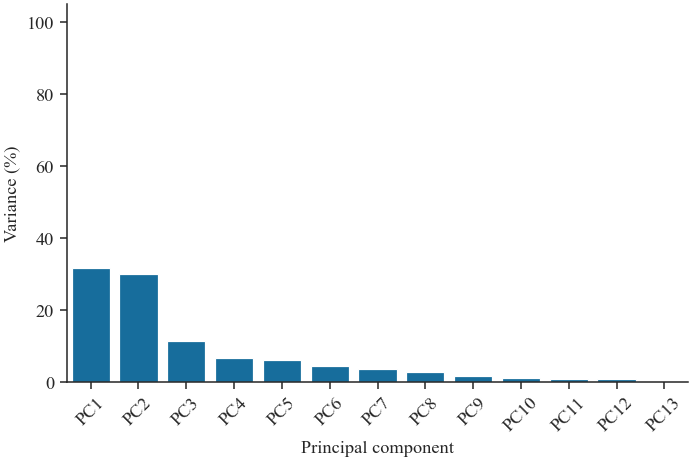

In [16]:
pca_scree("Water_Pumlen")

## Interpretation limits

PCA describes covariance of the included environmental variables. Lake or season
separation is descriptive and is not a significance test or evidence of environmental
control of carbon storage. Repeated sites remain repeated observations. The percentage
shown on each axis states how much total standardised variance that projection retains.
For carbon-pool relationships, return to the paired scatter plots in notebook 01.

## Conclusions and ecological interpretation

- Soil and water PCAs characterise **different environmental compartments**; compare their gradients conceptually rather than equating their component axes.
- The percentage printed on PC1 and PC2 gives the proportion of variance explained **within the standardised variables included in that PCA**. No carbon-stock variance explained or causal effect is implied.
- A point near another point has a similar multivariate environmental profile along the **displayed** components. Arrows represent correlations between variables and the principal components; their orientation is informative only to the extent that variables are represented well on PC1–PC2.
- The combined biplot labels only five variables to preserve print readability; consult the complete loading tables saved to CSV before asserting which variables dominate a component.
- Interpret any separation of wetlands or seasons as descriptive. Site-level repeated measures, temporal confounding, and correlated inputs (e.g., EC and TDS) should be addressed before formal ecological claims.